# The Absolute Most Basic Diffraction Analysis of a Sample Suitable for Total Beginners: The Aluminum Files.

-----------

Here's the basic idea: 

1.   Load an image image of aluminum.
2.   Plot it, just to make sure it's reasonable.
3.   Calibrate it so we can know our scale and do something reasonable in nanometers.
4.   Measure things about spots in the diffraction patterns in reciprocal space.
5.   Do "math stuff" to solve for material structure and spacing in the normal world.
6.   Profit!


So let's do the simple part first: load the image.

In [1]:
%matplotlib widget

import hyperspy.api as hs

hs.preferences.GUIs.enable_traitsui_gui = False  # needed to suppress harmless traitsui-vs-widget warning

In [2]:
from __future__ import print_function
import matplotlib.pyplot as plt
import matplotlib

backends = matplotlib.rcsetup.interactive_bk
# validate backends
backends_valid = []
for b in backends:
    try:
        plt.switch_backend(b)
        backends_valid += [b]
    except:
        continue
print(backends_valid)



AttributeError: module 'matplotlib.rcsetup' has no attribute 'interactive_bk'

In [3]:
from __future__ import print_function, division, absolute_import
from pylab import *
import time

import matplotlib.backends
import matplotlib.pyplot as p
import os.path


def is_backend_module(fname):
    """Identifies if a filename is a matplotlib backend module"""
    return fname.startswith('backend_') and fname.endswith('.py')

def backend_fname_formatter(fname): 
    """Removes the extension of the given filename, then takes away the leading 'backend_'."""
    return os.path.splitext(fname)[0][8:]

# get the directory where the backends live
backends_dir = os.path.dirname(matplotlib.backends.__file__)

# filter all files in that directory to identify all files which provide a backend
backend_fnames = filter(is_backend_module, os.listdir(backends_dir))

backends = [backend_fname_formatter(fname) for fname in backend_fnames]

print("supported backends: \t" + str(backends))

# validate backends
backends_valid = []
for b in backends:
    try:
        p.switch_backend(b)
        backends_valid += [b]
    except:
        continue

print("valid backends: \t" + str(backends_valid))


# try backends performance
for b in backends_valid:

    ion()
    try:
        p.switch_backend(b)


        clf()
        tstart = time.time()               # for profiling
        x = arange(0,2*pi,0.01)            # x-array
        line, = plot(x,sin(x))
        for i in arange(1,200):
            line.set_ydata(sin(x+i/10.0))  # update the data
            draw()                         # redraw the canvas

        print(b + ' FPS: \t' , 200/(time.time()-tstart))
        ioff()

    except:
        print(b + " error :(")

supported backends: 	['template', 'qtcairo', 'qt', 'gtk3cairo', 'tkagg', 'gtk4agg', 'qt5agg', 'qt5', 'gtk3agg', 'cairo', 'pdf', 'wxagg', 'pgf', 'mixed', 'macosx', 'gtk4', 'tkcairo', 'gtk3', 'wxcairo', 'nbagg', 'webagg_core', 'gtk4cairo', 'wx', 'qt5cairo', 'svg', 'webagg', 'ps', 'qtagg', 'agg']
valid backends: 	['template', 'pdf', 'pgf', 'macosx', 'nbagg', 'svg', 'webagg', 'ps', 'agg']
template FPS: 	 211.14108855629277
pdf FPS: 	 204.80030000043945
pgf FPS: 	 217.34594442637965
macosx FPS: 	 222.1990067989875
nbagg FPS: 	 225.08562185995044
svg FPS: 	 225.15219754411862
webagg FPS: 	 224.54926100594417
ps FPS: 	 220.99599585754748
agg FPS: 	 219.3829112889538


In [2]:
s = hs.load("../aluminumData/Al-DP-problem.tif")
print(s)



<Signal2D, title: , dimensions: (|501, 334)>


### Calibration

Question: does that image come straight off the 'scope in units of 1/nm? Does it fundamentally, physically capture diffraction patterns, or _something_ process an image into this?


In [4]:
print(s.calibrate())

None


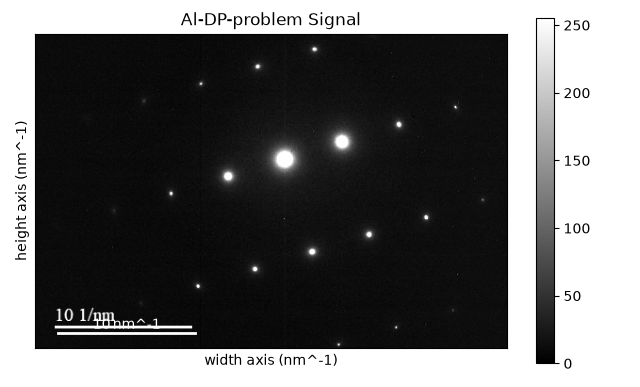

In [5]:
s.plot()

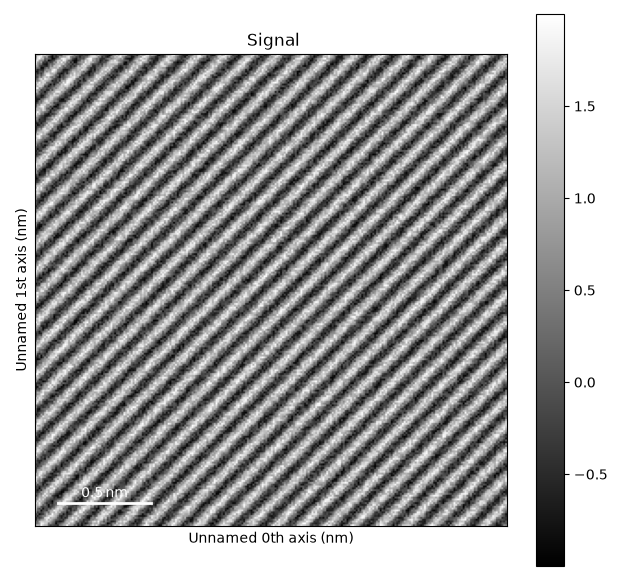

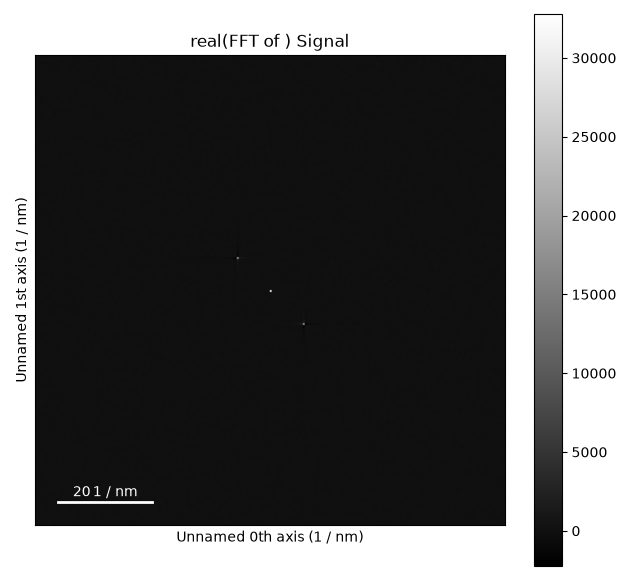

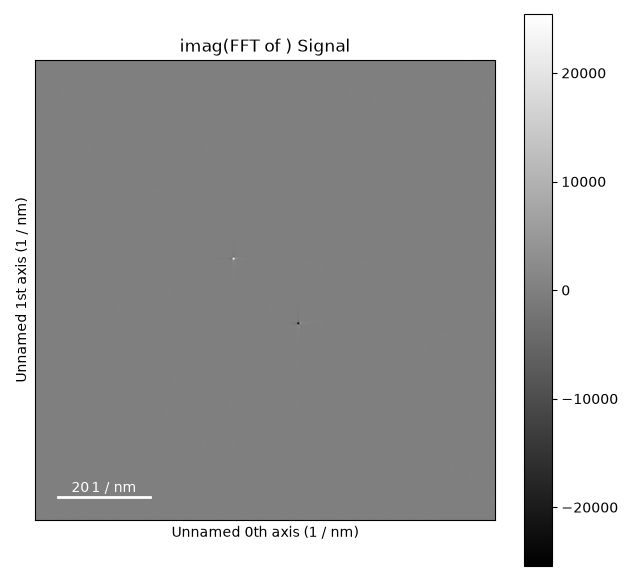

In [6]:
#im = hs.data.wave_image()
#fft_shifted = im.fft(shift=True)
#fft_shifted.plot()

im = hs.data.wave_image()
im.plot()
fft_shifted = im.fft(shift=True)
fft_shifted.plot()

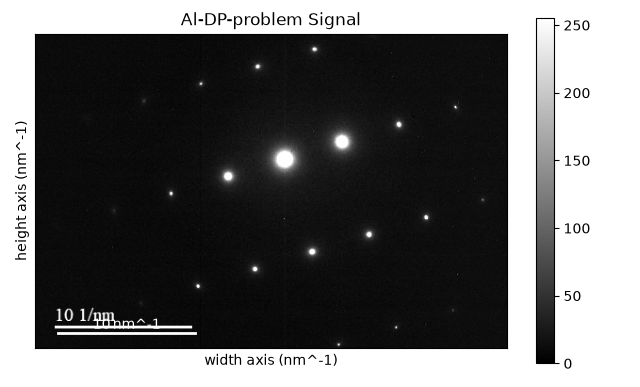

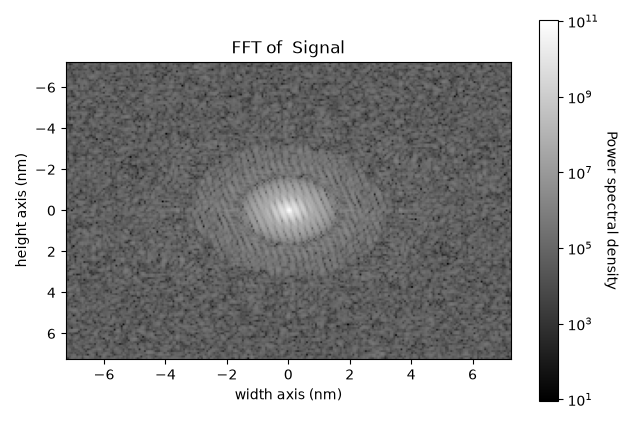

In [7]:
new_s = s
rectangular_roi = hs.roi.RectangularROI()
new_s.plot()
roi2D = rectangular_roi.interactive(new_s, color="red")

s_fft = hs.interactive(roi2D.fft, apodization=True, shift=True, recompute_out_event=None)
s_fft.plot(power_spectrum=True)


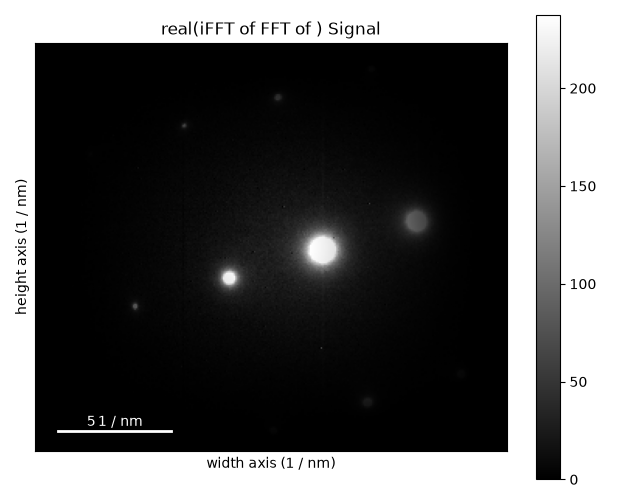

In [13]:
#sff = sf_result.ifft()
sff = s_fft.ifft()
sff.plot()